In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [31]:
file_path = r"C:\Users\DELL\Desktop\OIBSIP\DataAnalytics-L1-EDARetailSales\retail_sales_dataset.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (1000, 9)


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [32]:
print("Column Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nUnique Customers:", df["Customer ID"].nunique())

Column Names:
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 70.4 KB

Missing Values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amou

In [33]:
# Convert Date column to datetime
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Remove rows with missing values in important columns
df = df.dropna(subset=["Customer ID", "Date", "Total Amount"])

# Set reference date
reference_date = df["Date"].max() + pd.Timedelta(days=1)

# Calculate RFM values
rfm = df.groupby("Customer ID").agg(
    Recency=("Date", lambda x: (reference_date - x.max()).days),
    Frequency=("Transaction ID", "nunique"),
    Monetary=("Total Amount", "sum")
).reset_index()

print("RFM Analysis Completed!")
print("Number of Customers:", len(rfm))

rfm.head(10)

RFM Analysis Completed!
Number of Customers: 1000


,Customer ID,Recency,Frequency,Monetary
0,CUST001,39,1,150
1,CUST002,309,1,1000
2,CUST003,354,1,30
3,CUST004,226,1,500
4,CUST005,241,1,100
5,CUST006,252,1,30
6,CUST007,295,1,50
7,CUST008,314,1,100
8,CUST009,20,1,600
9,CUST010,87,1,200


In [34]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

df = df.dropna(
    subset=["Customer ID", "Date", "Total Amount"]
)

reference_date = df["Date"].max() + pd.Timedelta(days=1)

rfm = df.groupby("Customer ID").agg(
    Recency=("Date", lambda x: (reference_date - x.max()).days),
    Frequency=("Transaction ID", "nunique"),
    Monetary=("Total Amount", "sum")
).reset_index()

rfm.head(10)

,Customer ID,Recency,Frequency,Monetary
0,CUST001,39,1,150
1,CUST002,309,1,1000
2,CUST003,354,1,30
3,CUST004,226,1,500
4,CUST005,241,1,100
5,CUST006,252,1,30
6,CUST007,295,1,50
7,CUST008,314,1,100
8,CUST009,20,1,600
9,CUST010,87,1,200


In [35]:
print("RFM Dataset Information:")
print(rfm.info())

print("\nSummary Statistics:")
display(rfm.describe())

print("\nMissing Values:")
print(rfm.isnull().sum())

RFM Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Customer ID  1000 non-null   str  
 1   Recency      1000 non-null   int64
 2   Frequency    1000 non-null   int64
 3   Monetary     1000 non-null   int64
dtypes: int64(3), str(1)
memory usage: 31.4 KB
None

Summary Statistics:


,Recency,Frequency,Monetary
count,1000.000000,1000.0,1000.000000
mean,182.982000,1.0,456.000000
std,105.276773,0.0,559.997632
min,1.000000,1.0,25.000000
25%,90.000000,1.0,60.000000
50%,186.500000,1.0,135.000000
75%,269.000000,1.0,900.000000
max,366.000000,1.0,2000.000000



Missing Values:
Customer ID    0
Recency        0
Frequency      0
Monetary       0
dtype: int64


In [36]:
from sklearn.preprocessing import StandardScaler

# Select features for clustering
features = rfm[["Recency", "Frequency", "Monetary"]]

# Standardize the features
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(features)

print("RFM data standardized successfully!")
print("Scaled data shape:", rfm_scaled.shape)

RFM data standardized successfully!
Scaled data shape: (1000, 3)


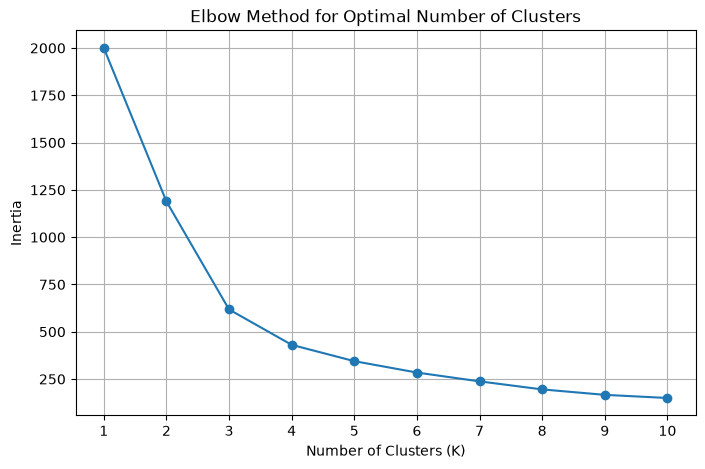

In [37]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia_values = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(rfm_scaled)
    inertia_values.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia_values, marker="o")
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [38]:
# Create 4 customer segments
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)

print("Customer Segmentation Completed!")

print("\nCustomers in Each Cluster:")
print(rfm["Cluster"].value_counts().sort_index())

rfm.head(10)

Customer Segmentation Completed!

Customers in Each Cluster:
Cluster
0    140
1    370
2    366
3    124
Name: count, dtype: int64


,Customer ID,Recency,Frequency,Monetary,Cluster
0,CUST001,39,1,150,1
1,CUST002,309,1,1000,0
2,CUST003,354,1,30,2
3,CUST004,226,1,500,2
4,CUST005,241,1,100,2
5,CUST006,252,1,30,2
6,CUST007,295,1,50,2
7,CUST008,314,1,100,2
8,CUST009,20,1,600,1
9,CUST010,87,1,200,1


In [39]:
# Analyze customer segments
cluster_summary = rfm.groupby("Cluster").agg(
    Customer_Count=("Customer ID", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean")
).round(2)

display(cluster_summary)

,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary
Cluster,,,,
0,140,270.52,1.0,1283.57
1,370,92.12,1.0,159.77
2,366,274.57,1.0,148.32
3,124,84.94,1.0,1313.71


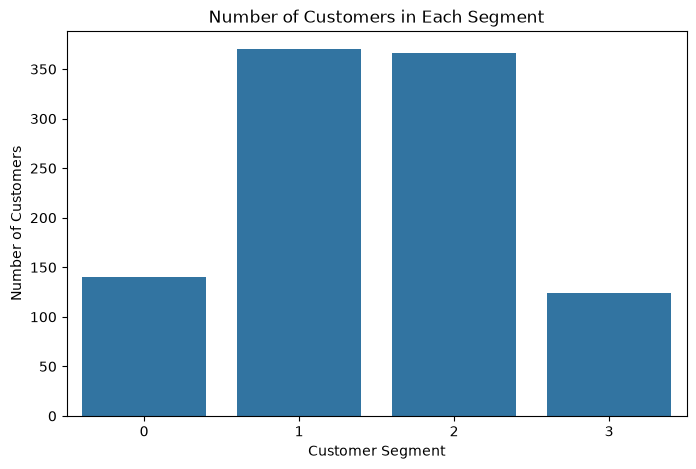

In [40]:
plt.figure(figsize=(8, 5))

sns.countplot(data=rfm, x="Cluster")

plt.title("Number of Customers in Each Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")

plt.show()

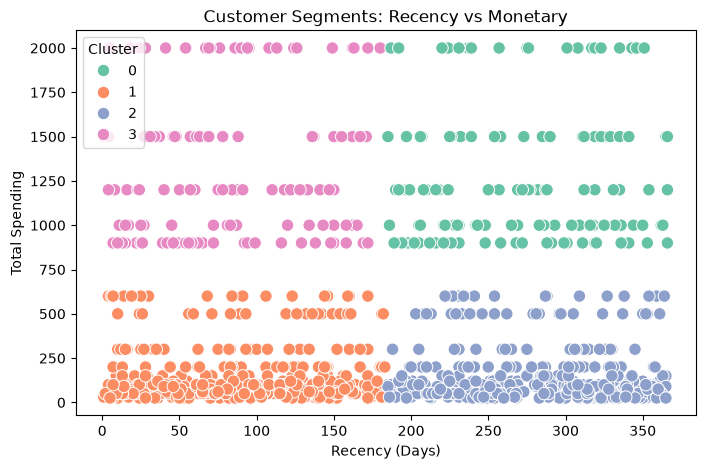

In [41]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=rfm,
    x="Recency",
    y="Monetary",
    hue="Cluster",
    palette="Set2",
    s=80
)

plt.title("Customer Segments: Recency vs Monetary")
plt.xlabel("Recency (Days)")
plt.ylabel("Total Spending")
plt.legend(title="Cluster")
plt.show()

In [42]:
for cluster_id, row in cluster_summary.iterrows():
    print(f"\nCustomer Segment {cluster_id}")
    print(f"Number of Customers: {row['Customer_Count']}")
    print(f"Average Recency: {row['Avg_Recency']:.2f} days")
    print(f"Average Purchase Frequency: {row['Avg_Frequency']:.2f}")
    print(f"Average Spending: {row['Avg_Monetary']:.2f}")


Customer Segment 0
Number of Customers: 140.0
Average Recency: 270.52 days
Average Purchase Frequency: 1.00
Average Spending: 1283.57

Customer Segment 1
Number of Customers: 370.0
Average Recency: 92.12 days
Average Purchase Frequency: 1.00
Average Spending: 159.77

Customer Segment 2
Number of Customers: 366.0
Average Recency: 274.57 days
Average Purchase Frequency: 1.00
Average Spending: 148.32

Customer Segment 3
Number of Customers: 124.0
Average Recency: 84.94 days
Average Purchase Frequency: 1.00
Average Spending: 1313.71


In [43]:
for cluster_id, row in cluster_summary.iterrows():
    print(f"\nCustomer Segment {cluster_id}:")

    if row["Avg_Recency"] <= cluster_summary["Avg_Recency"].median():
        print("- Customers purchased relatively recently.")

    if row["Avg_Frequency"] >= cluster_summary["Avg_Frequency"].median():
        print("- Encourage repeat purchases with loyalty rewards.")

    if row["Avg_Monetary"] >= cluster_summary["Avg_Monetary"].median():
        print("- Offer premium products and exclusive deals.")

    if (
        row["Avg_Recency"] > cluster_summary["Avg_Recency"].median()
        and row["Avg_Frequency"] < cluster_summary["Avg_Frequency"].median()
    ):
        print("- Send personalized offers to encourage customers to return.")

    print("- Use targeted marketing based on this segment's purchasing behavior.")


Customer Segment 0:
- Encourage repeat purchases with loyalty rewards.
- Offer premium products and exclusive deals.
- Use targeted marketing based on this segment's purchasing behavior.

Customer Segment 1:
- Customers purchased relatively recently.
- Encourage repeat purchases with loyalty rewards.
- Use targeted marketing based on this segment's purchasing behavior.

Customer Segment 2:
- Encourage repeat purchases with loyalty rewards.
- Use targeted marketing based on this segment's purchasing behavior.

Customer Segment 3:
- Customers purchased relatively recently.
- Encourage repeat purchases with loyalty rewards.
- Offer premium products and exclusive deals.
- Use targeted marketing based on this segment's purchasing behavior.


## Customer Segment Observations

The customers were grouped into four clusters using the K-Means algorithm based on Recency, Frequency, and Monetary values.

- **Recency:** Helps identify customers who purchased recently and those who may need re-engagement.
- **Frequency:** Helps identify customers who make purchases more often.
- **Monetary:** Helps identify customers who contribute more to total sales.
- **Marketing Strategy:** Businesses can use these metrics to create targeted offers, loyalty rewards, and re-engagement campaigns.

The characteristics of each cluster should be interpreted using the cluster summary table generated in this notebook.


## Marketing Recommendations

1. **Recent Customers:** Encourage repeat purchases with personalized product recommendations.
2. **Frequent Customers:** Offer loyalty points and repeat-purchase rewards.
3. **High-Spending Customers:** Provide premium offers and exclusive benefits.
4. **Inactive Customers:** Send re-engagement campaigns and special discounts.
5. **Targeted Marketing:** Use each cluster's Recency, Frequency, and Monetary values to personalize campaigns.

These recommendations should be refined using the actual statistics of each customer cluster.
